# Praktikum W6S2 Text Classification

## Langkah 1 Membaca dataset

Pertama kita baca file CSV yang sudah disiapkan

In [2]:
import pandas as pd

df = pd.read_csv('Text_classification.csv')
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


## Langkah 2 Preprocessing teks

Sebelum teks dipakai oleh model, kita bersihkan dulu, teks diubah menjadi huruf kecil angka dan tanda baca dihapus lalu kata katanya dipisah

In [3]:
# Download resource NLTK yang diperlukan
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

# Import library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower() # Ubah menjadi lowercase
    text = re.sub(r'\d+', '', text) # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
    words = word_tokenize(text) # Tokenisasi
    words = [word for word in words if word not in stopwords.words('english')] # Hapus stopwords
    words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)

# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!



Hasil Preprocessing:
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


## Langkah 3 Mengubah label kategori

Kolom cateory masih berisi tulisan ham dan spam Supaya bisa dipakai dalam proses klasifikasi

In [4]:
# Ubah label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})

# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


## Langkah 4 Membagi data training dan testing

Data dibagi menjadi 80% untuk training dan 20% untuk testing. Data training dipakai untuk melatih model, sedangkan data testing dipakai untuk melihat hasil prediksinya

In [11]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur dan label
X = df['clean_text']
y = df['Category']

# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Langkah 5 Ekstraksi fitur dengan TF-IDF

Model tidak bisa langsung memproses kalimat sebagai teks biasa, jadi teks diubah menjadi fitur numerik menggunakan TF-IDF

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000) # Menggunakan bigram
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("\nTF-IDF Shape (Train):", X_train_tfidf.shape)


TF-IDF Shape (Train): (4457, 5000)


## Langkah 6 Melatih model Naïve Bayes

Pada bagian ini digunakan MultinomialNB yaitu model Naïve Bayes yang umum dipakai untuk klasifikasi teks. Setelah model dibuat dengan model dilatih menggunakan fitur training dan kemudian digunakan untuk memprediksi data testing.

In [13]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model Naïve Bayes
model = MultinomialNB(alpha=0.1)

# Train model
model.fit(X_train_tfidf, y_train)

# Prediksi hasil
y_pred = model.predict(X_test_tfidf)

## Langkah 7 Evaluasi model

Kita cek akurasi dan classification report untuk melihat performa model. Selain accuracy, laporan ini menampilkan precision, recall, f1-score

In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



## Langkah 8 Menampilkan Confusion Matrix

Confusion matrix menunjukkan jumlah prediksi yang benar dan salah. TN dan TP adalah prediksi yang benar, sedangkan FP dan FN adalah prediksi yang keliru

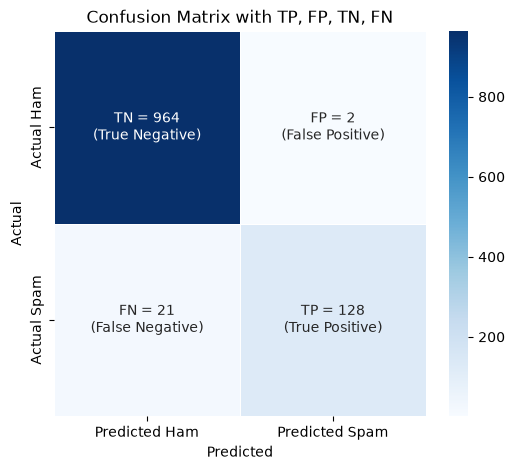

In [17]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat dataframe confusion matrix
df_conf_matrix = pd.DataFrame(
    conf_matrix,
    index=['Actual Ham', 'Actual Spam'],
    columns=['Predicted Ham', 'Predicted Spam']
)

# Label untuk TP, FP, FN, TN
labels = np.array([
    ["TN = {}\n(True Negative)".format(TN), "FP = {}\n(False Positive)".format(FP)],
    ["FN = {}\n(False Negative)".format(FN), "TP = {}\n(True Positive)".format(TP)]
])

# Plot heatmap dengan keterangan
plt.figure(figsize=(6,5))
ax = sns.heatmap(
    df_conf_matrix, annot=labels, fmt='', cmap='Blues',
    linewidths=0.5, cbar=True
)

# Tambahkan label
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, FP, TN, FN')
plt.show()

## Langkah 9 Mencoba prediksi pada teks baru

Terakhir kita masukkan dua contoh pesan baru,  Pesan tersebut dibersihkan dengan fungsi yang sama diubah ke fitur TF-IDF menggunakan vectorizer yang sudah dibuat lalu diprediksi oleh model yang kita buat

In [18]:
# Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
             "Hey, are you coming to the party tonight?"]

# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]

# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)

# Prediksi
predictions = model.predict(new_texts_tfidf)

# Output hasil prediksi
for text, label in zip(new_texts, predictions):
    print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham
